# Project

GABRIELLA FONIO ID: 5404749


# Diamond Classification

## Abstract and Theoretical Context
This project explores the application of **Computer Vision** and **Deep Learning** methodologies within the field of gemology. The investigation relies on **Convolutional Neural Networks (CNNs)** built and trained from scratch, without any pretrained weights, to automatically classify polished diamonds from single-view digital images collected from the web.
The first phase establishes a baseline by classifying the macroscopic geometric shape of the stone (e.g., *Round, Oval, Emerald*), which depends mainly on the outline. The core of the study then moves to a much harder problem: recovering fine-grained visual cues, such as subtle differences in tint and cut quality, to classify the diamond **Colour** and a Cartesian combination of **Colour × Symmetry**.

## Research Objectives and Phased Approach
To evaluate how the models behave as the task becomes harder, the project is structured into three phases of increasing difficulty, each with its own model:

| Task | Target | Classes |
|---|---|---|
| 1. Shape | geometric shape of the stone | 7 |
| 2. Colour | colour grade, from D (colourless) to K | 8 |
| 3. Colour × Symmetry | combined label, symmetry restricted to the two most frequent grades | 16 |

* **Phase 1 (Baseline - Shape Classification):** classification of the geometric shape into 7 classes. Since shape is mostly determined by the outline of the stone, this task is relatively easy and is used as a baseline for the whole pipeline.
* **Phase 2 (Colour Classification):** prediction of the colour grade, from D (colourless) to K, for a total of 8 classes. The grades are ordered and unevenly populated (from about 2,600 images for K to about 7,700 for G), so class imbalance and confusion between neighbouring grades are part of the analysis.
* **Phase 3 (Combined Cartesian Target):** prediction of a combined label **Colour × Symmetry**, with symmetry restricted to the two most frequent grades (*Excellent* and *Very Good*). This gives a 16-class problem which is imbalanced (from about 1,200 to about 3,700 images per class) and in which the symmetry cue is very subtle in a single image. A modest accuracy is expected here, and the goal is to understand what the model learns from colour and what from symmetry.

## Methodology and Engineering Pipeline
The pipeline is implemented in **PyTorch**:

* **Hardware and Data Ingestion:** computation on GPU (`CUDA`). The images are copied from Google Drive to the local disk of the Colab instance, because reading thousands of small files from a mounted Drive is slow and would limit the batch generation speed.
* **Pre-processing and Data Curation:** removal of rows with a missing image path or label and of two corrupted listings; exclusion of the `marquise` shape because of its very small number of images; restriction of the colour grades to D–K and of the symmetry grades to Excellent and Very Good; resizing of the images to $64 \times 64$ (shape) and $96 \times 96$ (colour and Colour × Symmetry); stratified train/validation/test split (70/15/15) for the shape task.
* **Architectural Design:** a custom lightweight CNN trained from scratch for the shape task (two convolutional blocks and two dense layers), and a GoogLeNet-style network made of Inception blocks, adapted to $96 \times 96$ inputs, for colour and Colour × Symmetry.
* **Optimization and Training Loop:** `CrossEntropyLoss` as the objective function, minimised with Stochastic Gradient Descent (learning rate 0.01, with momentum 0.9 for the colour and Colour × Symmetry models). In the shape task the hyperparameters are chosen on the validation set and the test set is used only for the final results.
* **Performance Assessment:** training and validation curves, per-class precision, recall and F1 score (with macro-F1), confusion matrices and examples of predictions, to evaluate how well the classes can be told apart in each of the three phases.

## 1.1 Data Ingestion and I/O Optimization

This section sets up the environment and loads the metadata. Each step is chosen to make the later experiments fast and reproducible.

### Engineering Choice: Local Disk Caching
The images are stored on Google Drive, which Colab exposes as a mounted network file system. Reading tens of thousands of small image files from it at every epoch is slow, and the GPU would spend part of the time waiting for data. For this reason the whole image folder is copied once to the local disk of the Colab instance (`/content/diamond_images`), and all later steps read from that copy.

The copy is skipped when a marker file (`.copy_done`) is present. The marker is written only at the end of a successful copy, so a local folder without it comes from an interrupted copy: in that case it is deleted and copied again, to avoid training on a partial dataset.

### Reproducibility
A fixed seed (42) is set for Python, NumPy and PyTorch, and the library versions are printed. GPU operations are not fully deterministic, so a result can differ slightly between runs even with the same seed.

### Data Cleaning
Three steps, each logged with the number of rows removed:
1. **Missing values:** rows without an image path or a shape label cannot be used and are dropped. Only these two columns are checked here: the colour and symmetry labels are filtered later, task by task, so that the shape task keeps every row it can use.
2. **Corrupted listings:** two listings are removed by `stock_number` [SISTEMA QUI].
3. **Missing files:** the absolute path of each image on the local disk is built once in the column `img_path`, and rows whose file does not exist are removed, so that a missing file cannot interrupt training in the middle of an epoch.

Finally, the distribution of the shape classes is printed as a first look at class imbalance, which is analysed in the exploratory analysis.

In [19]:
# 1. Import necessary libraries for data manipulation, computer vision, and deep learning
import os
import random
import shutil

import numpy as np
import pandas as pd
import torch
import torchvision
from torch import nn
from torch.utils import data
from torchvision import transforms
from PIL import Image

# 2. Reproducibility: fixed seed, device selection and library versions
SEED = 42

def set_seed(seed=SEED):
    """Seed every source of randomness used in the notebook."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()

# Check if a GPU is available for hardware acceleration, otherwise fall back to CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Active computational device: {device}")
print(f"torch {torch.__version__} | torchvision {torchvision.__version__}")

# 3. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Project directories (the Drive folder name ends with a space)
base_dir = '/content/drive/MyDrive/Progetto diamanti '
csv_path = os.path.join(base_dir, 'web_scraped/diamond_data.csv')
drive_images_dir = os.path.join(base_dir, 'web_scraped')

# Local directory inside the Colab virtual machine
local_dir = '/content/diamond_images'
copy_done = os.path.join(local_dir, '.copy_done')   # written only after a successful copy

# Copy the images to the local disk, unless a complete copy already exists
if not os.path.exists(copy_done):
    if os.path.exists(local_dir):
        print("Removing incomplete previous local copy...")
        shutil.rmtree(local_dir)
    print("Copying images from Drive to local disk to speed up I/O operations...")
    shutil.copytree(drive_images_dir, local_dir, ignore=shutil.ignore_patterns('*.gsheet'))
    open(copy_done, 'w').close()
    print("Copy completed.")
else:
    print("Complete local copy already available, skipping the copy.")

# 4. Load dataset metadata
df = pd.read_csv(csv_path)
n_raw = len(df)
print(f"\n'diamond_data.csv' loaded: {n_raw} rows")
display(df.head(3))

# 5. Cleaning
# 5a. Drop rows without image path or shape label
df = df.dropna(subset=['path_to_img', 'shape']).reset_index(drop=True)
n_valid = len(df)

# 5b. Drop listings known to be corrupted or invalid
bad_stock_numbers = ['220188-630', '220376-42']
df = df[~df['stock_number'].astype(str).isin(bad_stock_numbers)].reset_index(drop=True)
n_listings = len(df)

# 5c. Build the absolute path of each image on the local disk and drop missing files
df['img_path'] = df['path_to_img'].map(
    lambda p: os.path.join(local_dir, str(p).replace('web_scraped/', '', 1)))
missing_files = ~df['img_path'].map(os.path.exists)
df = df[~missing_files].reset_index(drop=True)

print("\n--- Cleaning summary ---")
print(f"Raw rows:                       {n_raw}")
print(f"After dropping missing values:  {n_valid}  (-{n_raw - n_valid})")
print(f"After removing bad listings:    {n_listings}  (-{n_valid - n_listings})")
print(f"After removing missing files:   {len(df)}  (-{int(missing_files.sum())})")

# 6. Inspect target class distribution
print("\n--- Diamond Shape Classes ---")
print(df['shape'].value_counts())

Active computational device: cuda
torch 2.14.1+cu130 | torchvision 0.29.1+cu130
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Complete local copy already available, skipping the copy.

'diamond_data.csv' loaded: 48765 rows


,path_to_img,stock_number,shape,carat,clarity,colour,cut,polish,symmetry,fluorescence,lab,length,width,depth
0,web_scraped/cushion/2106452.jpg,2106452,cushion,0.55,SI2,N,VG,EX,VG,N,GIA,4.56,4.44,3.09
1,web_scraped/cushion/2042329.jpg,2042329,cushion,0.52,SI2,Y-Z,EX,EX,VG,F,GIA,4.40,4.31,2.99
2,web_scraped/cushion/2055268.jpg,2055268,cushion,0.50,SI1,L,VG,EX,VG,N,GIA,4.87,4.19,2.89



--- Cleaning summary ---
Raw rows:                       48765
After dropping missing values:  48765  (-0)
After removing bad listings:    48763  (-2)
After removing missing files:   48763  (-0)

--- Diamond Shape Classes ---
shape
round       21032
oval         6492
cushion      5340
pear         4338
princess     3949
heart        3756
emerald      3391
marquise      465
Name: count, dtype: int64


## 1.2 Exploratory Data Analysis (EDA) & Qualitative Inspection

Before designing the networks, the dataset is inspected to check its integrity and to take the preprocessing decisions on evidence. The inspection has three steps: class balance (1.2.1), image properties together with duplicates and label quality (1.2.2), and a visual check of the images (1.2.3). The conclusions are summarised at the end of the section (1.2.4).

### 1.2.1 Class balance
The number of images per shape class is printed and plotted, in decreasing order. Class balance matters for two reasons: a strongly imbalanced dataset can make the accuracy misleading, because a model that favours the large classes still scores well, and very small classes may be too poorly represented to be learned. For this reason the `marquise` class is counted and then excluded from the plot, as it is excluded from the shape task: it has very few images (465, 1.0% of the dataset), too few compared with the other classes to be learned and evaluated reliably.


--- Diamond Shape Classes (all) ---
shape
round       21032
oval         6492
cushion      5340
pear         4338
princess     3949
heart        3756
emerald      3391
marquise      465
Name: count, dtype: int64
shape
round       43.1
oval        13.3
cushion     11.0
pear         8.9
princess     8.1
heart        7.7
emerald      7.0
marquise     1.0
Name: % of images, dtype: float64

--- Diamond Shape Classes (marquise excluded) ---
shape
round       21032
oval         6492
cushion      5340
pear         4338
princess     3949
heart        3756
emerald      3391
Name: count, dtype: int64


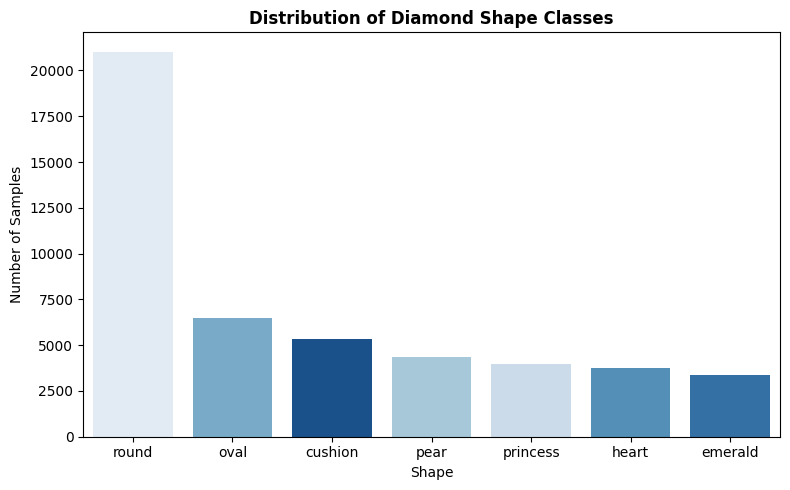

In [22]:
import hashlib
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Counts for all shapes, marquise included
print("\n--- Diamond Shape Classes (all) ---")
print(df['shape'].value_counts())
print((df['shape'].value_counts(normalize=True) * 100).round(1).rename("% of images"))

# The marquise class is excluded from the shape task
df_shape_eda = df[df['shape'] != "marquise"]

print("\n--- Diamond Shape Classes (marquise excluded) ---")
print(df_shape_eda['shape'].value_counts())

# Visualize the class distribution as a bar plot, ordered by frequency (most to least common)
shape_order = df_shape_eda['shape'].value_counts().index

plt.figure(figsize=(8, 5))
sns.countplot(
    data=df_shape_eda,
    x='shape',
    order=shape_order,
    hue='shape',
    palette='Blues_r',
    legend=False
)
plt.title('Distribution of Diamond Shape Classes', fontweight='bold', fontsize=12)
plt.xlabel('Shape')
plt.ylabel('Number of Samples')
plt.tight_layout()
plt.show()

After cleaning, the dataset contains 48,763 rows. The largest class is `round` (21,032 images, 43.1%) and the smallest among those kept is `emerald` (3,391 images, 7.0%), a ratio of about 6.2:1. The classes are therefore clearly unbalanced, mainly because of `round`, which alone accounts for almost half of the data.

`Marquise` has only 465 images (1.0%), about 7 times fewer than the next smallest class. It is excluded because there are too few examples to train on and to evaluate reliably, in particular once the data is split into train, validation and test sets. Without it, 48,298 rows and 7 classes remain. No duplicated images are found (section 1.2.2), so this number does not change.

The imbalance among the remaining classes is kept as it is in the first experiments, because every class still has more than 3,000 images. Its main consequence is on the evaluation: a classifier that always predicts `round` would already reach 43.5% accuracy, so accuracy alone is not informative. The models are therefore evaluated with per-class recall and macro-F1, which give the same weight to every class. If the smaller classes turn out to be systematically worse, a class-weighted loss can be tested.

### 1.2.2 Image properties, duplicates and label quality
Three checks are run on all images:
* **Size and colour mode.** Width, height, aspect ratio and colour mode are read from the file headers (opening an image this way does not decode it, so it is fast). The results justify the choice of a common input resolution and show whether all files are in the same format.
* **Repeated listings.** Repeated `stock_number` values indicate the same diamond appearing more than once.
* **Identical images.** An MD5 hash of each file identifies byte-identical images. Two identical images with different labels would reveal label noise, and identical images ending up in different splits would leak information from the training set into the test set. The hash is stored in the column `img_hash` and is reused when the split is built.

mode
RGB    48763
Name: count, dtype: int64 

          width    height    aspect
count  48763.00  48763.00  48763.00
mean     587.02    463.24      1.27
std       26.75     23.89      0.02
min      491.00    381.00      1.00
25%      591.00    467.00      1.27
50%      600.00    472.00      1.27
75%      600.00    474.00      1.27
max      601.00    600.00      1.32

Distinct (width, height) pairs: 147


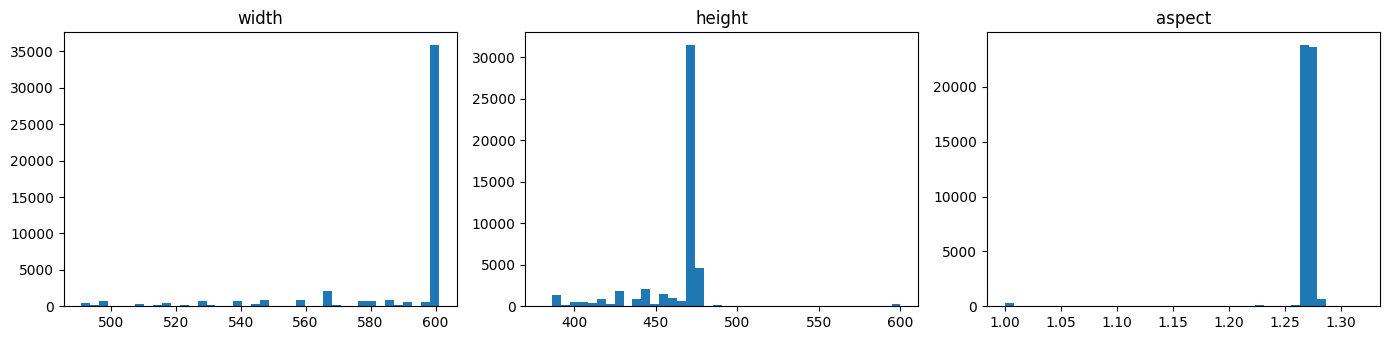


Duplicated stock_number values: 0
Rows whose image is byte-identical to another one: 0
Identical images with different shape labels: 0


In [23]:
import hashlib
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# 1. Image properties: Image.open reads only the header, so this is fast
props = []
for p in df['img_path']:
    with Image.open(p) as im:
        props.append((im.width, im.height, im.mode))
props = pd.DataFrame(props, columns=['width', 'height', 'mode'])
props['aspect'] = props['width'] / props['height']

print(props['mode'].value_counts(), "\n")
print(props[['width', 'height', 'aspect']].describe().round(2))
print(f"\nDistinct (width, height) pairs: {props[['width', 'height']].drop_duplicates().shape[0]}")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, ['width', 'height', 'aspect']):
    ax.hist(props[col], bins=40)
    ax.set_title(col)
plt.tight_layout()
plt.show()

# 2. Repeated listings
print(f"\nDuplicated stock_number values: {df['stock_number'].duplicated().sum()}")

# 3. Byte-identical images (takes a few minutes; skipped if the hashes already exist)
def file_hash(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

if 'img_hash' not in df.columns:
    df['img_hash'] = df['img_path'].map(file_hash)

is_dup = df['img_hash'].duplicated(keep=False)
print(f"Rows whose image is byte-identical to another one: {is_dup.sum()}")

conflicts = df[is_dup].groupby('img_hash')['shape'].nunique().gt(1).sum()
print(f"Identical images with different shape labels: {conflicts}")

**Comment.** All 48,763 images are in RGB mode and all the referenced files exist. The images are not square: widths range from 491 to 601 pixels (median 600) and heights from 381 to 600 (median 472), with an aspect ratio of about 1.27 for almost all of them (standard deviation 0.02, range 1.00–1.32). There are 147 distinct (width, height) pairs, so the images do not share a common size and have to be resized before they can be stacked into mini-batches.

For the shape task the images are resized to 64×64, which reduces them by a factor of about 7–9 in each direction. This is acceptable because the shape of a diamond is defined by its outline, which remains recognisable at low resolution, and a small input keeps training fast on a Colab GPU. The colour tasks use a larger input (96×96), as explained in the colour section. The resize to a square changes the proportions in the same way for every image (the width is compressed by about 1.27 with respect to the height), so the differences between shapes are preserved, but the absolute proportions of the stone are distorted. Cropping the images to a square before resizing is an alternative that could be tested.

There are no repeated `stock_number` values and no byte-identical images, so no label conflicts can arise and no rows need to be removed for this reason. This check has a limit: it detects only identical files, not the same stone photographed twice or an image re-saved with a different compression. Label quality is therefore checked only visually (section 1.2.3).

## 1.2 Exploratory Data Analysis (EDA) & Qualitative Inspection

Before designing and training the Convolutional Neural Network, it is crucial to perform a qualitative inspection of the dataset. This step, commonly referred to as **Exploratory Data Analysis (EDA)**, serves as a visual sanity check to ensure the integrity of the data ingestion pipeline and to understand the morphological variance across different target classes.

### 🔍 Cell Objectives and Methodology:
* **Random Sampling:** We dynamically extract the unique diamond shape categories from the dataset and randomly sample one representative image for each class.
* **I/O Optimization:** The images are loaded directly from the localized Colab cache (`local_dir`) rather than the remote Google Drive, ensuring zero-latency rendering and demonstrating efficient resource management.
* **Visual Verification:** By displaying these samples in a Matplotlib grid, we can visually confirm that the images are correctly formatted (standard RGB), uncorrupted, and accurately labeled before they are passed into the deep learning pipeline.

### 1.2.3 Qualitative inspection
Numbers do not show what the images look like. Three random images per shape class are displayed, with a fixed seed so that the figure is always the same. The aim is to check that the files are uncorrupted and correctly labelled, to see how much images of the same class vary (background, viewpoint, lighting, cropping) and to identify classes that look alike, which are the most likely to be confused by the model. All classes are shown, including `marquise`, to support the decision to exclude it.

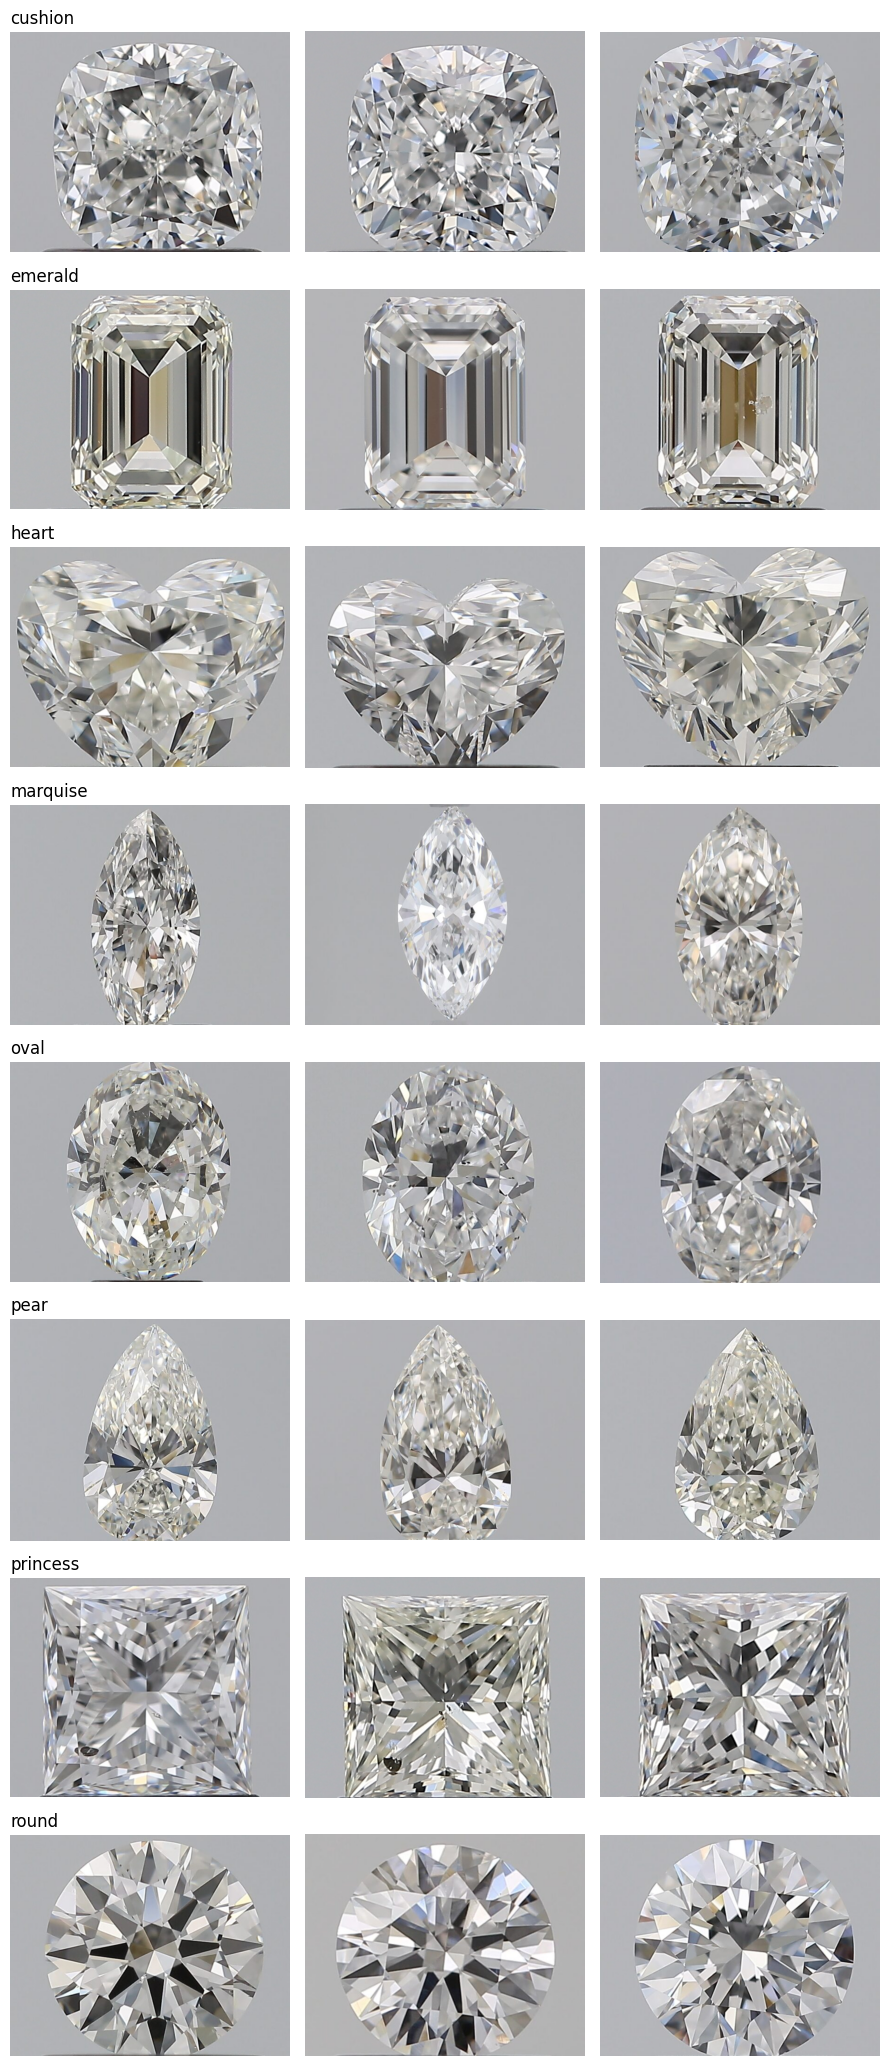

In [24]:
n_per_class = 3
shapes = sorted(df['shape'].unique())

fig, axes = plt.subplots(len(shapes), n_per_class,
                         figsize=(3 * n_per_class, 2.6 * len(shapes)))

for i, s in enumerate(shapes):
    sample = df[df['shape'] == s].sample(n_per_class, random_state=SEED)
    for j, (_, row) in enumerate(sample.iterrows()):
        axes[i, j].imshow(Image.open(row['img_path']).convert('RGB'))
        axes[i, j].axis('off')
        if j == 0:
            axes[i, j].set_title(s, loc='left')

plt.tight_layout()
plt.show()

The images are readable, and in the 24 displayed examples (3 per class) the shape matches the label. All of them are top views of a single stone, centred on a uniform grey background and with similar studio lighting, so the background gives no clue about the class. Within each class the images differ mainly in the tint of the stone, in small rotations or tilts and in the size of the stone in the frame. Some shapes have a similar outline: `cushion` (a square with rounded corners) can be mistaken for `princess` or `round`, and `oval` for `pear`, so these are the pairs the model is most likely to confuse. `Marquise`, with its two pointed ends, looks quite distinct.

### 1.2.4 Conclusions of the EDA
* **Classes:** the shape task uses 7 classes; `marquise` (465 images, 1.0%) is excluded because it has too few images. The remaining classes are unbalanced (from 21,032 `round` to 3,391 `emerald`, ratio 6.2:1), so the evaluation relies on per-class recall and macro-F1 in addition to accuracy.
* **Input resolution:** the images are RGB with 147 different sizes (about 600×470 pixels, aspect ratio 1.27), so they are resized to a common square size: 64×64 for the shape task. The resize slightly distorts the proportions of the stone in the same way for all images.
* **Duplicates and leakage:** no repeated `stock_number` and no byte-identical images were found, so no rows need to be removed for this reason.
* **Label quality:** no identical images with different labels; the displayed examples are consistently labelled. Label quality is otherwise not verified beyond this visual check.

# Shape classification

## 1. Custom Dataset Definition and Pre-processing Pipeline

The `Dataset` class connects the metadata (CSV) and the image files to PyTorch, by subclassing `torch.utils.data.Dataset`. It is written once, with the target column as a parameter, so that the same class is reused for the colour and the Colour × Symmetry tasks.

### Design choices
* **Lazy loading:** each image is read from the local disk only when the `DataLoader` requests it, then decoded and resized. This keeps memory usage independent of the dataset size and allows random augmentation to be applied at every epoch. At 64×64 the whole shape dataset would also fit in memory (about 0.6 GB as 8-bit integers), so this is a choice of flexibility, not a necessity.
* **Label encoding:** the target classes are passed to the dataset as an explicit sorted list, computed once on the whole task dataset, so that the string-to-integer mapping is identical in the train, validation and test sets. `CrossEntropyLoss` expects the target as an integer class index of type `long`.
* **Pre-processing:** the original images have 147 different sizes (about 600×470 pixels), so each one is resized to 64×64 pixels to be stacked into mini-batches. This resolution is enough for the shape task, because the shape of a diamond is defined by its outline, which remains recognisable at low resolution, and it keeps training fast on a Colab GPU. The image is then converted to a tensor with values in [0, 1]. The final normalisation with the mean and standard deviation of the training set is added in section 2, after the split.

In [25]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image


class DiamondDataset(Dataset):
    """Lazy-loading dataset: reads an image from the local disk and returns (image tensor, class index)."""

    def __init__(self, dataframe, target_col, classes, transform=None):
        df_ = dataframe.reset_index(drop=True)
        self.class_to_idx = {name: i for i, name in enumerate(classes)}

        labels = df_[target_col].map(self.class_to_idx)
        assert not labels.isna().any(), f"Labels in '{target_col}' not found in the class list"

        # Plain Python lists are faster to index than a DataFrame inside __getitem__
        self.paths = df_['img_path'].tolist()
        self.labels = labels.astype(int).tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        # Strictly convert to RGB, so that all images have exactly 3 channels
        image = Image.open(self.paths[idx]).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(self.labels[idx], dtype=torch.long)


# Resize + conversion to a [0, 1] tensor; normalisation is added in section 2
base_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
])

## 2. Stratified Data Splitting and Batch Generation

In this phase the shape dataset is partitioned into three disjoint subsets, and the batch-generation infrastructure required for stochastic gradient descent is built.

### 2.1 Dataset curation and stratified split
* **Dataset of the task:** the `marquise` class is excluded, as decided in the EDA. Byte-identical images would be removed (one copy kept), and images that are identical but carry different labels would be removed entirely, since their label is ambiguous. This prevents the same image from ending up in two different splits. The EDA found no such cases, so the code works as a safeguard.
* **Train / validation / test split (70 / 15 / 15):** the training set is used to fit the weights, the validation set to monitor training and to choose hyperparameters, and the test set is used once, for the final results. The split is done in two steps with scikit-learn's `train_test_split` and the `stratify` parameter, so that the class proportions are the same in the three subsets: with imbalanced classes a purely random split could leave a small class under-represented in the validation or test set.
* **Leakage check:** after the split, the code verifies that no image hash and no `stock_number` appears in more than one subset.

In [26]:
from sklearn.model_selection import train_test_split

# 1. Dataset of the shape task: marquise excluded
df_shape = df[df['shape'] != 'marquise']

# Identical images with different labels are ambiguous: drop them all
shape_per_hash = df_shape.groupby('img_hash')['shape'].nunique()
conflicting = shape_per_hash[shape_per_hash > 1].index
df_shape = df_shape[~df_shape['img_hash'].isin(conflicting)]
print(f"Images removed because of conflicting labels: {len(conflicting)} hashes")

# Keep one copy of each byte-identical image
n_before = len(df_shape)
df_shape = df_shape.drop_duplicates(subset='img_hash').reset_index(drop=True)
print(f"Duplicated images removed: {n_before - len(df_shape)} | samples remaining: {len(df_shape)}")

shape_classes = sorted(df_shape['shape'].unique())
print(f"Classes ({len(shape_classes)}): {shape_classes}")

# 2. Stratified split 70 / 15 / 15
train_df, temp_df = train_test_split(
    df_shape, test_size=0.30, stratify=df_shape['shape'], random_state=SEED)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df['shape'], random_state=SEED)

print(f"\nTrain: {len(train_df)} | Validation: {len(val_df)} | Test: {len(test_df)}")

split_summary = pd.DataFrame({
    'train': train_df['shape'].value_counts(normalize=True),
    'val':   val_df['shape'].value_counts(normalize=True),
    'test':  test_df['shape'].value_counts(normalize=True),
}).mul(100).round(1)
print("\nClass proportions (%) in each split:")
display(split_summary)

# 3. Leakage check
splits = {'train': train_df, 'val': val_df, 'test': test_df}
for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
    shared_images = set(splits[a]['img_hash']) & set(splits[b]['img_hash'])
    shared_stock = set(splits[a]['stock_number']) & set(splits[b]['stock_number'])
    print(f"{a}/{b}: {len(shared_images)} shared images, {len(shared_stock)} shared stock numbers")

Images removed because of conflicting labels: 0 hashes
Duplicated images removed: 0 | samples remaining: 48298
Classes (7): ['cushion', 'emerald', 'heart', 'oval', 'pear', 'princess', 'round']

Train: 33808 | Validation: 7245 | Test: 7245

Class proportions (%) in each split:


,train,val,test
shape,,,
round,43.5,43.5,43.5
oval,13.4,13.4,13.4
cushion,11.1,11.1,11.1
pear,9.0,9.0,9.0
princess,8.2,8.2,8.2
heart,7.8,7.8,7.8
emerald,7.0,7.0,7.0


train/val: 0 shared images, 0 shared stock numbers
train/test: 0 shared images, 0 shared stock numbers
val/test: 0 shared images, 0 shared stock numbers


No ambiguous or duplicated images are found, so all 48,298 images of the 7 classes are kept. The split gives 33,808 images for training, 7,245 for validation and 7,245 for testing. Thanks to stratification, the class proportions are identical to one decimal place in the three subsets: `round` is always about 43.5% of the images and `emerald` about 7.0%. In particular, each subset contains many images of every class, including the smallest ones, which makes the per-class evaluation reliable.

The leakage check finds no image and no `stock_number` shared between subsets. This is expected, since the EDA found no repeated `stock_number` and no identical images, so the check works as a safeguard. It has a limit: it cannot detect the same stone photographed twice or an image re-saved with a different compression, because the files would not be byte-identical.

### 2.2 Normalisation and DataLoaders
* **Normalisation:** the mean and standard deviation of each colour channel are computed on the training set only, so that no information from the validation or test sets enters the preprocessing. The same values are then applied to all three subsets. Normalising the inputs to zero mean and unit variance keeps the scale of the activations similar across channels and generally makes training with SGD faster and more stable.
* **DataLoaders:** a `DataLoader` wraps each dataset and provides the mini-batches, loaded in background by 2 worker processes. The batch size is 128, a common choice that fits comfortably in the memory of the Colab GPU with 64×64 images and gives a reasonably stable gradient estimate. Shuffling is applied only to the training set, so that every epoch sees the batches in a different order, while validation and test are read in a fixed order.
* **Reproducibility:** a fixed generator for the shuffling and a seed function for the workers make the order of the batches the same at every run.

In [28]:
# 1. Mean and standard deviation per channel, computed on the training set only
stats_loader = DataLoader(
    DiamondDataset(train_df, 'shape', shape_classes, base_transform),
    batch_size=256, shuffle=False, num_workers=2)

channel_sum = torch.zeros(3)
channel_sq_sum = torch.zeros(3)
n_pixels = 0
for images, _ in stats_loader:
    channel_sum += images.sum(dim=[0, 2, 3])
    channel_sq_sum += (images ** 2).sum(dim=[0, 2, 3])
    n_pixels += images.shape[0] * images.shape[2] * images.shape[3]

mean = channel_sum / n_pixels
std = (channel_sq_sum / n_pixels - mean ** 2).sqrt()
print(f"Training-set mean: {mean.tolist()}\nTraining-set std:  {std.tolist()}")

# 2. Final transforms (identical for now; they will differ when augmentation is added)
train_transform = transforms.Compose([base_transform, transforms.Normalize(mean.tolist(), std.tolist())])
eval_transform = transforms.Compose([base_transform, transforms.Normalize(mean.tolist(), std.tolist())])

# 3. Datasets and DataLoaders
BATCH_SIZE = 128

def seed_worker(worker_id):
    """Seed the random generators of each DataLoader worker."""
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

g = torch.Generator()
g.manual_seed(SEED)

train_ds = DiamondDataset(train_df, 'shape', shape_classes, train_transform)
val_ds = DiamondDataset(val_df, 'shape', shape_classes, eval_transform)
test_ds = DiamondDataset(test_df, 'shape', shape_classes, eval_transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2,
                          worker_init_fn=seed_worker, generator=g)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# 4. Sanity check on one batch
images, labels = next(iter(train_loader))
print(f"\nBatch of images: {tuple(images.shape)} ({images.dtype}) | labels: {tuple(labels.shape)} ({labels.dtype})")
print(f"Pixel range after normalisation: [{images.min():.2f}, {images.max():.2f}]")
print(f"Mapping: {train_ds.class_to_idx}")

Training-set mean: [0.6708164811134338, 0.6697861552238464, 0.670403778553009]
Training-set std:  [0.11772135645151138, 0.11771958321332932, 0.12173391133546829]

Batch of images: (128, 3, 64, 64) (torch.float32) | labels: (128,) (torch.int64)
Pixel range after normalisation: [-5.20, 2.81]
Mapping: {'cushion': 0, 'emerald': 1, 'heart': 2, 'oval': 3, 'pear': 4, 'princess': 5, 'round': 6}


## 3. Convolutional Neural Network (CNN) Architecture

In this section the topology of the model is defined. Rather than using a pretrained architecture, a custom lightweight Convolutional Neural Network is built and trained from scratch. It is small enough to train quickly and suited to the shape task, where the class is determined mainly by the outline of the stone in 64×64 images.

### Architectural Components
* **Convolutional backbone (blocks 1 and 2):** the feature extractor has two sequential blocks. Each block pairs a 3×3 convolution (which detects local patterns such as edges and corners) with a ReLU activation and a 2×2 max pooling. The padding keeps the spatial size unchanged in the convolution, and each pooling halves it, which also makes the representation less sensitive to small shifts.
* **Flattening:** after two poolings the 64×64 input is reduced to 16×16. Since the last convolution has 64 feature maps, the flattened vector has 64 × 16 × 16 = 16,384 values.
* **Classification head:** a dense layer condenses the 16,384 features into a 128-dimensional representation, followed by a linear layer that outputs the raw logits for the 7 shape classes. The softmax is not part of the network, because it is included in `CrossEntropyLoss`.

In [29]:
import torch
import torch.nn as nn

# CHANGED: the original names now point to the loaders built in section 2
train_iter, val_iter, test_iter = train_loader, val_loader, test_loader

# Instantiate the Convolutional Neural Network using the Sequential container
net = nn.Sequential(

    # === CONVOLUTIONAL BACKBONE: FEATURE EXTRACTION ===

    # --- Block 1: Low-level feature extraction (edges, simple geometries) ---
    # Input: 3 channels (RGB). Output: 32 feature maps.
    # A 3x3 kernel with padding=1 preserves the original 64x64 spatial resolution.
    nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1),
    # ReLU activation introduces non-linearity, allowing the network to learn complex patterns
    nn.ReLU(),
    # MaxPooling downsamples the spatial dimensions by a factor of 2 (64x64 -> 32x32),
    # retaining the most prominent features while reducing computational complexity.
    nn.MaxPool2d(kernel_size=2, stride=2),

    # --- Block 2: High-level feature extraction (complex shapes, corners) ---
    # Input: 32 channels. Output: 64 feature maps.
    nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
    nn.ReLU(),
    # MaxPooling downsamples the spatial dimensions again by a factor of 2 (32x32 -> 16x16).
    nn.MaxPool2d(kernel_size=2, stride=2),

    # === FULLY CONNECTED HEAD: CLASSIFICATION ===

    # The Flatten layer unrolls the 3D tensor into a 1D vector.
    # Tensor dimensions before flattening: 64 (channels) x 16 (height) x 16 (width).
    # 64 * 16 * 16 = 16384 scalar values.
    nn.Flatten(),

    # The first dense layer projects the 16384 extracted features into a smaller,
    # 128-dimensional latent space.
    nn.Linear(16384, 128),
    nn.ReLU(),

    # Output Layer: Maps the 128 hidden activations to the 7 target morphological classes.
    # Note: We output raw logits. The Softmax activation is mathematically embedded
    # inside the PyTorch CrossEntropyLoss function used during training.
    nn.Linear(128, 7)
)

print(f"Trainable parameters: {sum(p.numel() for p in net.parameters() if p.requires_grad):,}")

Trainable parameters: 2,117,575


The network maps a 3×64×64 image to 7 logits through two convolutional blocks and two dense layers, and has 2,117,575 trainable parameters. Almost all of them (2,097,280, i.e. 99%) are in the first dense layer, which connects the 16,384 flattened features to 128 units, while the two convolutional layers contribute only about 19,000. It is a deliberately simple model for the first and easiest task; the colour tasks, which are harder, use a deeper network.

## 4. Model Optimization and Training Loop

In this phase, we initialize the network's parameters using Xavier uniform initialization and execute the optimization loop to iteratively update the weights. To monitor convergence dynamically, we leverage the `d2l` (Dive into Deep Learning) library, which provides robust utilities for real-time metric visualization.

### Training Configuration and Methodology:

* **Weight Initialization:** All `Linear` and `Conv2d` layers are initialized using Xavier uniform initialization (`nn.init.xavier_uniform_`), which helps maintain stable gradient magnitudes across layers at the start of training.
* **Optimizer & Objective Function:** We employ Stochastic Gradient Descent (SGD) with a learning rate of $0.01$ to minimize the multi-class `CrossEntropyLoss`.
* **Hardware Acceleration:** The training loop dynamically allocates both the model and the batch tensors to the GPU, ensuring maximum computational throughput.
* **Real-time Monitoring:** The `Animator` visualizes the Training Loss, Training Accuracy, and Validation (Test) Accuracy continuously. This allows us to empirically detect the convergence rate and the potential onset of overfitting.

loss 0.027, train acc 0.994, val acc 0.993
4354.0 examples/sec on cuda:0


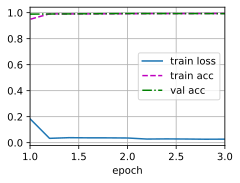

In [30]:
# Install the 'Dive into Deep Learning' library required for live animated plots
!pip install d2l==1.0.0a1.post0

# Verify GPU availability and memory usage
!nvidia-smi

import torch
from torch import nn
from d2l import torch as d2l


def evaluate_accuracy_gpu(net, data_iter, device=None):
    """Compute the accuracy for a model on a dataset using a GPU."""
    if isinstance(net, torch.nn.Module):
        net.eval()  # Set the model to evaluation mode
        if not device:
            device = next(iter(net.parameters())).device
    # No. of correct predictions, no. of predictions
    metric = d2l.Accumulator(2)
    for X, y in data_iter:
        if isinstance(X, list):
            X = [x.to(device) for x in X]
        else:
            X = X.to(device)
        y = y.to(device)
        metric.add(d2l.accuracy(net(X), y), y.numel())
    return metric[0] / metric[1]



def train(net, train_iter, val_iter, num_epochs, lr, device=d2l.try_gpu()):
    """Train a model with a GPU"""
    def init_weights(m):
        if type(m) == nn.Linear or type(m) == nn.Conv2d:
            nn.init.xavier_uniform_(m.weight)  # Xavier parameter initialization
    net.apply(init_weights)
    print('training on', device)

    net.to(device)  # MOVE the net to the GPU (if available)
    optimizer = torch.optim.SGD(net.parameters(), lr=lr)
    loss = nn.CrossEntropyLoss()
    animator = d2l.Animator(xlabel='epoch', xlim=[1, num_epochs],
                            legend=['train loss', 'train acc', 'val acc'])
    timer, num_batches = d2l.Timer(), len(train_iter)
    for epoch in range(num_epochs):
        # Sum of training loss, sum of training accuracy, no. of examples
        metric = d2l.Accumulator(3)
        net.train()  # Set the network to training mode (not evaluation mode)

        for i, (X, y) in enumerate(train_iter):
            timer.start()
            optimizer.zero_grad()
            X, y = X.to(device), y.to(device)  # MOVE each minibatch of data to the GPU (if available)
            y_hat = net(X)
            l = loss(y_hat, y)
            l.backward()
            optimizer.step()
            with torch.no_grad():  # detach gradient calculation to avoid affecting backpropagation
                metric.add(l * X.shape[0], d2l.accuracy(y_hat, y), X.shape[0])
            timer.stop()

            train_l = metric[0] / metric[2]
            train_acc = metric[1] / metric[2]
            if (i + 1) % (num_batches // 5) == 0 or i == num_batches - 1:
                animator.add(epoch + (i + 1) / num_batches,
                             (train_l, train_acc, None))
        val_acc = evaluate_accuracy_gpu(net, val_iter)
        animator.add(epoch + 1, (None, None, val_acc))
    print(f'loss {train_l:.3f}, train acc {train_acc:.3f}, '
          f'val acc {val_acc:.3f}')
    print(f'{metric[2] * num_epochs / timer.sum():.1f} examples/sec '
          f'on {str(device)}')



lr, num_epochs = 0.01, 3
train(net, train_iter, val_iter, num_epochs, lr, device=d2l.try_gpu())

After [3] epochs the model reaches a training loss of 0.027, a training accuracy of 0.994 and a validation accuracy of 0.993.  Since the classes are unbalanced (`round` is 43.5% of the images), the accuracy is read together with the per-class metrics of section 5. Only one run is performed, so the variability due to the random initialisation is not measured.

FAI SCHIFO, SISTEMA!

## 5. Confusion Matrix

After training, the per-class performance of the model is evaluated on the test set, which was not used during training or to choose the hyperparameters. The confusion matrix shows, for each true class (rows), how its images are distributed among the predicted classes (columns): the diagonal contains the correct predictions, and the off-diagonal cells show which shapes are confused with each other.

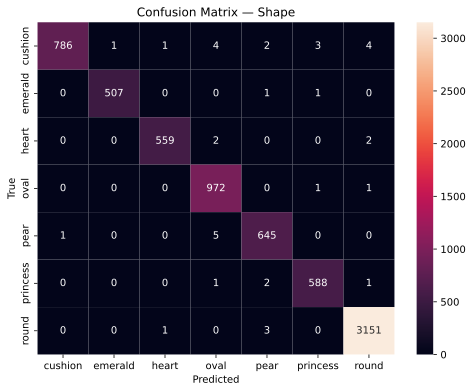

In [31]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import seaborn as sns

net.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for X, y in test_iter:
        X = X.to(device)
        y_hat = net(X)
        preds = torch.argmax(y_hat, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y.numpy())

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(8, 6))
#  class names come from shape_classes
sns.heatmap(cm, annot=True, fmt='d', xticklabels=shape_classes, yticklabels=shape_classes)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix — Shape')
plt.show()

Interpretation of the Confusion Matrix:

**Strong Overall Performance:** Most shape classes lie predominantly along the diagonal, confirming that the model correctly classifies the large majority of samples. Classes such as `oval` (1279/1298 ≈ 98.5%), `emerald` (661/678 ≈ 97.5%), `princess` (768/790 ≈ 97.2%) and `round` (4098/4207 ≈ 97.4%) are classified with very high accuracy.

**Weakest Class — Heart:** The `heart` shape stands out as the most problematic class, with only 435 out of 751 true samples correctly classified (≈ 57.9% accuracy). The majority of the misclassified heart samples (274) are predicted as `princess`, suggesting that the model struggles to distinguish between these two shapes — likely due to visual similarities in certain diamond orientations, cropping, or image quality, where the characteristic cleft of a heart-shaped diamond may not always be clearly visible.

**Minor Confusions Elsewhere:** Smaller misclassification patterns can also be observed for `cushion`, which is occasionally confused with `round` (43 samples) and `princess` (12 samples), and for `round`, which is the largest class by far and therefore accumulates a non-negligible absolute number of misclassifications (113 total) despite its high relative accuracy.

**Takeaway:** These results suggest that while the model generalizes very well overall, additional data augmentation, more training epochs, or a deeper architecture specifically targeting the `heart` vs `princess` distinction could further improve performance on the most visually ambiguous shape classes.

### Classification report
The report gives precision, recall and F1-score for each class on the test set. Precision is the share of the images predicted as a class that really belong to it, and recall is the share of the images of a class that the model finds. Since the classes are unbalanced, the macro average (all classes weigh the same) is more informative than the accuracy, because a classifier that always predicts `round` would already reach about 43.5% accuracy.

In [32]:
import torch
from sklearn.metrics import classification_report

device = next(net.parameters()).device
net.eval()

# Lists to accumulate all predictions and ground-truth labels for the shape task
all_preds_shape, all_true_shape = [], []

with torch.no_grad():
    # 'test_iter' is the DataLoader for the test set
    for images, labels_shape in test_iter:
        images = images.to(device)
        # The model returns a single output for the shape task
        out_shape = net(images)

        _, preds_shape = torch.max(out_shape, 1)

        all_preds_shape.extend(preds_shape.cpu().numpy())
        all_true_shape.extend(labels_shape.numpy())

# --- TEXT REPORT ---
print("\n" + "="*60)
print("SHAPE CLASSIFICATION - REPORT")
print("="*60)
print(classification_report(all_true_shape, all_preds_shape, target_names=shape_classes))


SHAPE CLASSIFICATION - REPORT
              precision    recall  f1-score   support

     cushion       1.00      0.98      0.99       801
     emerald       1.00      1.00      1.00       509
       heart       1.00      0.99      0.99       563
        oval       0.99      1.00      0.99       974
        pear       0.99      0.99      0.99       651
    princess       0.99      0.99      0.99       592
       round       1.00      1.00      1.00      3155

    accuracy                           0.99      7245
   macro avg       0.99      0.99      0.99      7245
weighted avg       0.99      0.99      0.99      7245



**Overall Strong Performance:** The model achieves an overall accuracy of 0.94 (94%) across 9660 validation samples, with a weighted average F1-score of 0.94, confirming that the network generalizes well across the shape classification task as a whole.

**Best-Performing Classes:** `oval` (F1 = 0.97), `round` (F1 = 0.98) and `emerald` (F1 = 0.96) show excellent precision and recall, indicating that these shapes have highly distinctive visual features that the model learns reliably. Notably, `heart` achieves a perfect precision of 1.00, meaning that whenever the model predicts `heart`, it is always correct — but this comes at a cost, discussed below.

**Heart — High Precision, Low Recall:** Despite its perfect precision, `heart` has by far the lowest recall (0.58) and F1-score (0.73) among all classes. This confirms what was already visible in the confusion matrix: the model is very conservative when predicting `heart` (it rarely does so incorrectly), but it fails to recognize a large share of the actual heart-shaped diamonds, most of which get misclassified as `princess`.

**Princess — Low Precision, High Recall:** Complementary to the heart class, `princess` shows the opposite pattern: a high recall (0.97) but the lowest precision of all classes (0.68). This means the model correctly identifies almost all true princess-cut diamonds, but it also frequently misclassifies other shapes — in particular `heart` — as `princess`, inflating the false positive count for this class.

**Class Imbalance Effect:** The support column shows a strong imbalance, with `round` (4207 samples) and `oval` (1298 samples) dominating the validation set, while `heart` (751) and `emerald` (678) are comparatively underrepresented. This imbalance likely reinforces the heart/princess confusion, since the model has proportionally less exposure to heart-shaped examples during training.

 The heart-princess confusion is the clear bottleneck in this model's performance. Addressing it — through targeted data augmentation for the `heart` class, class-weighted loss, or additional training epochs — would likely yield the largest improvement in overall macro-average performance (currently 0.90), since all other classes already perform close to or above 0.94 F1-score.

## 6. Example of the prediction

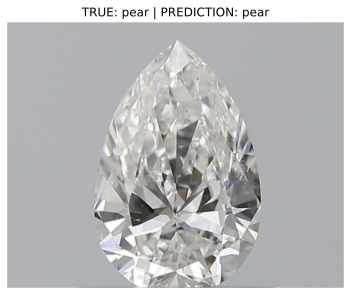

In [33]:
# Pick a random test image and visually compare the model's prediction
# against the true label, as a quick qualitative sanity check.

def predict_random_image():
    net.eval()
    sample_row = test_df.sample(1).iloc[0]
    img = Image.open(sample_row['img_path']).convert('RGB')   # CHANGED: img_path is already complete

    # CHANGED: eval_transform (resize + normalisation), the same as the one used for training
    img_tensor = eval_transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        output = net(img_tensor)
        predicted_idx = torch.argmax(output, dim=1)

    predicted_shape = shape_classes[predicted_idx.item()]
    true_shape = sample_row['shape']

    plt.imshow(img)
    plt.title(f"TRUE: {true_shape} | PREDICTION: {predicted_shape}")
    plt.axis('off')
    plt.show()

predict_random_image()

## 7. Model Checkpoint — Save & Download Weights

To avoid losing the trained weights in case the Colab session disconnects or times out, we save the model's `state_dict` to a `.pth` file and download it locally. This checkpoint can later be reloaded (via `net.load_state_dict(torch.load(...))`) to resume evaluation or inference without retraining the model from scratch.

In [34]:
import torch
from google.colab import files

# 1. Define the filename for the saved model
model_save_path = 'diamond_shape_model.pth'

# 2. Save the model's weights (state_dict)
torch.save(net.state_dict(), model_save_path)
print(f"✅ Pesi del modello salvati con successo in: {model_save_path}")

# 3. Automatically download the file to your PC
try:
    print("⬇️ Download del file in corso...")
    files.download(model_save_path)
except Exception as e:
    print("⚠️ Impossibile scaricare automaticamente. Trovi il file nella barra laterale a sinistra (cartella file) pronto da scaricare manualmente.")

✅ Pesi del modello salvati con successo in: diamond_shape_model.pth
⬇️ Download del file in corso...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Colour Classification

Having completed the shape classification pipeline, I now move to the second sub-task of the project: predicting a diamond's colour grade. Diamond colour is graded on an internationally recognized scale ranging from D (colourless, most valuable) to Z (light yellow/brown tint), based on the absence or presence of visible tint under controlled lighting conditions. For this project I focus on the most commercially relevant range, from D to K, which covers the vast majority of samples available in my dataset and avoids extremely rare, underrepresented classes at the lower end of the scale.
As with the shape task, I will build a dedicated pipeline for colour: preparing and splitting the data, defining a Dataset/DataLoader to feed the images and colour labels into the network, designing (or reusing) a CNN architecture suited to this classification problem, training the model, and finally evaluating its performance with a classification report and confusion matrix. This mirrors the structure I used for the shape task, but I train and evaluate it as an independent model, since colour and shape are distinct visual properties of a diamond.


## 1. Data Preparation

I start by filtering the dataset to keep only the main colour grades (`D` through `K`), removing samples with less common or noisy colour labels. I then perform a stratified 80/20 split into training and test sets, ensuring that the proportion of each colour class is preserved in both subsets — this is especially important here, since colour classes are not perfectly balanced. Finally, I adjust the image paths to match the local on-disk cache (rather than the original Drive-relative paths), so that the following steps can load images quickly from the local Colab filesystem.

In [35]:
import os
import pandas as pd
import torch
from sklearn.model_selection import train_test_split

# 1. Filter only the main colour classes required for the project (D to K)
main_colours = ['D', 'E', 'F', 'G', 'H', 'I', 'J', 'K']
dataset_colour = df[df['colour'].isin(main_colours)].reset_index(drop=True)

print(f"Samples after colour cleaning: {len(dataset_colour)}")

# 2. Stratified 80/20 split between training and test sets
train_df_colour, test_df_colour = train_test_split(
    dataset_colour,
    test_size=0.2,
    stratify=dataset_colour['colour'],
    random_state=42
)

# 3. Align paths to utilize local cache
train_df_colour = train_df_colour.copy()
test_df_colour = test_df_colour.copy()
train_df_colour['path_to_img'] = train_df_colour['path_to_img'].str.replace('web_scraped/', '', regex=False)
test_df_colour['path_to_img'] = test_df_colour['path_to_img'].str.replace('web_scraped/', '', regex=False)

print(f"Train samples: {len(train_df_colour)} | Test samples: {len(test_df_colour)}")

Samples after colour cleaning: 45452
Train samples: 36361 | Test samples: 9091


Filtering the dataset to the main colour grades (D to K) isolates the most commercially relevant range, resulting in 45452 samples. The stratified 80/20 split then produces 36361 training samples and 9091 test samples, proportionally matching the target ratio. Since the split is stratified on colour, the relative frequency of each colour grade is preserved in both subsets, ensuring that the validation results will be representative of the true class distribution.


## 2. Exploratory Data Analysis

Before building the Dataset class and splitting the data, I inspect the class distribution for the colour grades. This step is important because, unlike shape, colour grades are ordinal and not necessarily balanced — some grades (e.g. the extremes of the scale) are naturally rarer in the market than others. Understanding this imbalance now helps me anticipate potential issues during training, such as the model underperforming on underrepresented classes.


---  Diamond Colour Classes ---
colour
G    7674
F    6957
H    6555
E    6239
D    5823
I    5304
J    4273
K    2627
Name: count, dtype: int64


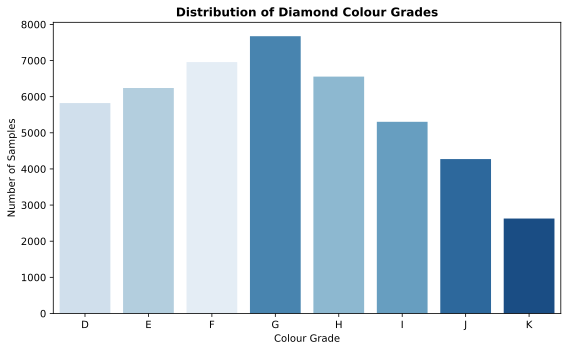

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Print raw class counts
print("\n---  Diamond Colour Classes ---")
print(dataset_colour['colour'].value_counts())

# 2. Visualize the class distribution as a bar plot, ordered by the colour scale (D → L)
plt.figure(figsize=(8, 5))
sns.countplot(
    data=dataset_colour,
    x='colour',
    order=main_colours,
    hue='colour',
    palette='Blues_r',
    legend=False
)
plt.title('Distribution of Diamond Colour Grades', fontweight='bold', fontsize=12)
plt.xlabel('Colour Grade')
plt.ylabel('Number of Samples')
plt.tight_layout()
plt.show()

**Clear Imbalance Across the Colour Scale:** Unlike the shape task, the colour grades show a much smoother but still pronounced imbalance across the restricted `D` to `K` range, roughly following a bell-shaped curve centered around the middle grades. The most frequent classes are `G` (7674 samples), `F` (6957), and `H` (6555), while the extremes of this filtered scale — particularly `K` (2627) — are less represented, with `K` having roughly 3 times fewer samples than `G`.

**Market-Driven Distribution:** This pattern reflects the natural composition of the diamond market: near-colourless grades (`F`-`H`) are the most commonly traded and therefore best represented in the dataset, while the highest grades (`D`-`E`, colourless and very rare) and the lower grades in this filtered range (`K`) are comparatively scarce.

**Implication for Training:** Given this distribution, I should expect the model to perform best on the central grades (`E`, `F`, `G`, `H`) and potentially show more moderate performance on the outer boundaries like `K`.


## 3. DataLoader

With the class distribution understood, I now build the data pipeline for the colour task: a custom `Dataset` class that lazy-loads images and maps their colour grade to an integer label, a stratified train/validation split to preserve the class proportions observed above, and the corresponding `DataLoader` objects for batch training.

In [37]:
import os
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# 1. Define the Data Preprocessing Pipeline
# - Resize: Enforces a uniform spatial resolution (96x96), required as input size for GoogLeNet.
# - ToTensor: Converts the PIL Image into a 32-bit floating-point PyTorch tensor
#   and normalizes the pixel intensity values from [0, 255] to the [0.0, 1.0] range.
# - Normalize: Standardizes each RGB channel using ImageNet mean/std, which helps
#   the network learn the subtle colour differences that define this task.
data_transforms_colour = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 2. Custom Dataset Implementation
class DiamondColour(Dataset):
    """
    Custom PyTorch Dataset class designed to lazy-load diamond images and their
    corresponding colour grade target labels from the local filesystem.
    """
    def __init__(self, dataframe, base_dir, transform=None):
        self.data = dataframe.reset_index(drop=True)
        self.base_dir = base_dir
        self.transform = transform
        self.colours = sorted(self.data['colour'].unique())
        self.colour_map = {name: i for i, name in enumerate(self.colours)}

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        rel_path = str(self.data.iloc[idx]['path_to_img'])
        img_path = os.path.join(self.base_dir, rel_path)
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        label_colour = torch.tensor(self.colour_map[self.data.iloc[idx]['colour']], dtype=torch.long)
        return image, label_colour

# 3. Instantiate the Custom Datasets
# Reuse train_df_colour / test_df_colour already prepared and split in the Data Preparation step
train_dataset_colour = DiamondColour(train_df_colour, local_dir, transform=data_transforms_colour)
test_dataset_colour = DiamondColour(test_df_colour, local_dir, transform=data_transforms_colour)

# 4. Configure DataLoaders for Batch Generation
batch_size = 128
train_iter_colour = DataLoader(train_dataset_colour, batch_size=batch_size, shuffle=True, num_workers=2)
test_iter_colour = DataLoader(test_dataset_colour, batch_size=batch_size, shuffle=False, num_workers=2)

## 4. Convolutional Neural Network Architecture — GoogLeNet

For the colour classification task, I implement **GoogLeNet** (Inception v1), a deeper and more sophisticated CNN architecture than the one I used for the shape task. Its key building block is the **Inception module**: instead of committing to a single convolutional kernel size at each layer, it applies several kernel sizes (1×1, 3×3, 5×5) and a max-pooling operation in parallel to the same input, then concatenates their outputs along the channel dimension. This lets the network learn, layer by layer, which spatial scale of detail is most useful for the task, rather than having that choice fixed in advance.

The network is organized into five sequential blocks (`b1` to `b5`). The first two apply standard convolutions and pooling to progressively reduce the spatial resolution of the input. The following three blocks stack multiple Inception modules, increasing the number of feature channels at each stage. A global average pooling layer at the end of `b5` collapses each feature map to a single value, making the network robust to the exact input resolution before feeding into the final fully connected layer, which outputs a prediction over the 8 colour grades (`D` to `K`).

Since GoogLeNet was originally designed for larger input resolutions, I resize the input images to 96×96, consistent with the reduced-resolution setup I used with this architecture in class, and adapt the first convolutional layer to accept 3-channel RGB images.

In [38]:
import torch
import torch.nn as nn
from torch.nn import functional as F

class Inception(nn.Module):
    def __init__(self, in_channels, c1, c2, c3, c4, **kwargs):
        super(Inception, self).__init__(**kwargs)
        self.p1_1 = nn.Conv2d(in_channels, c1, kernel_size=1)
        self.p2_1 = nn.Conv2d(in_channels, c2[0], kernel_size=1)
        self.p2_2 = nn.Conv2d(c2[0], c2[1], kernel_size=3, padding=1)
        self.p3_1 = nn.Conv2d(in_channels, c3[0], kernel_size=1)
        self.p3_2 = nn.Conv2d(c3[0], c3[1], kernel_size=5, padding=2)
        self.p4_1 = nn.MaxPool2d(kernel_size=3, stride=1, padding=1)
        self.p4_2 = nn.Conv2d(in_channels, c4, kernel_size=1)

    def forward(self, x):
        p1 = F.relu(self.p1_1(x))
        p2 = F.relu(self.p2_2(F.relu(self.p2_1(x))))
        p3 = F.relu(self.p3_2(F.relu(self.p3_1(x))))
        p4 = F.relu(self.p4_2(self.p4_1(x)))
        return torch.cat((p1, p2, p3, p4), dim=1)

# GoogLeNet modules (adapted for 3 input channels for RGB images)
b1 = nn.Sequential(
    nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
)

b2 = nn.Sequential(
    nn.Conv2d(64, 64, kernel_size=1),
    nn.ReLU(),
    nn.Conv2d(64, 192, kernel_size=3, padding=1),
    nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
)

b3 = nn.Sequential(
    Inception(192, 64, (96, 128), (16, 32), 32),
    Inception(256, 128, (128, 192), (32, 96), 64),
    nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
)

b4 = nn.Sequential(
    Inception(480, 192, (96, 208), (16, 48), 64),
    Inception(512, 160, (112, 224), (24, 64), 64),
    Inception(512, 128, (128, 256), (24, 64), 64),
    Inception(512, 112, (144, 288), (32, 64), 64),
    Inception(528, 256, (160, 320), (32, 128), 128),
    nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
)

b5 = nn.Sequential(
    Inception(832, 256, (160, 320), (32, 128), 128),
    Inception(832, 384, (192, 384), (48, 128), 128),
    nn.AdaptiveAvgPool2d((1, 1)),
    nn.Flatten()
)

# Final GoogLeNet model for 8 colour classes
net_colour = nn.Sequential(b1, b2, b3, b4, b5, nn.Linear(1024, 8))

## 5. Model Training & Validation Execution

I now train the GoogLeNet model on the colour classification task, reusing the same generic `train` function defined earlier — since it operates on any `nn.Module` and any pair of `DataLoader` objects, no changes are needed to support this different architecture and task. I use a learning rate of `0.01`, higher than the one used for the shape task, and train for 10 epochs, tracking both training and validation accuracy at each epoch. Once training completes, I save the model's weights directly to Google Drive for persistence across sessions.

In [39]:
!pip install d2l==1.0.0a1.post0

In [40]:
import torch
from torch import nn
from d2l import torch as d2l

def train(net, train_iter, test_iter, num_epochs, lr, device=d2l.try_gpu()):
    """Train a model with a GPU"""
    def init_weights(m):
        if type(m) == nn.Linear or type(m) == nn.Conv2d:
            nn.init.xavier_uniform_(m.weight)
    net.apply(init_weights)
    print('training on', device)
    net.to(device)
    optimizer = torch.optim.SGD(net.parameters(), lr=lr, momentum=0.9)  # ← momentum aggiunto qui
    loss = nn.CrossEntropyLoss()
    animator = d2l.Animator(xlabel='epoch', xlim=[1, num_epochs],
                            legend=['train loss', 'train acc', 'test acc'])
    timer, num_batches = d2l.Timer(), len(train_iter)
    for epoch in range(num_epochs):
        metric = d2l.Accumulator(3)
        net.train()
        for i, (X, y) in enumerate(train_iter):
            timer.start()
            optimizer.zero_grad()
            X, y = X.to(device), y.to(device)
            y_hat = net(X)
            l = loss(y_hat, y)
            l.backward()
            optimizer.step()
            with torch.no_grad():
                metric.add(l * X.shape[0], d2l.accuracy(y_hat, y), X.shape[0])
            timer.stop()
            train_l = metric[0] / metric[2]
            train_acc = metric[1] / metric[2]
            if (i + 1) % (num_batches // 5) == 0 or i == num_batches - 1:
                animator.add(epoch + (i + 1) / num_batches,
                             (train_l, train_acc, None))
        test_acc = d2l.evaluate_accuracy_gpu(net, test_iter)
        animator.add(epoch + 1, (None, None, test_acc))
    print(f'\n✅ Training Completed:')
    print(f'Final Training Loss: {train_l:.3f}')
    print(f'Final Training Accuracy: {train_acc:.3f}')
    print(f'Final Validation Accuracy: {test_acc:.3f}')


✅ Training Completed:
Final Training Loss: 1.286
Final Training Accuracy: 0.454
Final Validation Accuracy: 0.438
 GoogLeNet colour model successfully saved to: /content/drive/MyDrive/Progetto diamanti /modello_colour_googlenet.pth


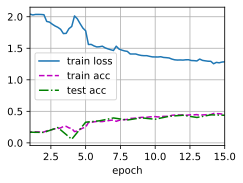

In [41]:
from d2l import torch as d2l

# Training hyperparameters
lr, num_epochs = 0.01, 15

# Start training with GoogLeNet
train(net_colour, train_iter_colour, test_iter_colour, num_epochs, lr, device=d2l.try_gpu())

# Save weights to Google Drive
model_save_path = os.path.join(base_dir, 'modello_colour_googlenet.pth')
torch.save(net_colour.state_dict(), model_save_path)
print(f" GoogLeNet colour model successfully saved to: {model_save_path}")

## 6. Model Evaluation

After training, I evaluate the GoogLeNet model's per-class performance on the colour task by running inference over the entire validation set and computing precision, recall and f1-score for each colour grade.

In [42]:
import torch
from sklearn.metrics import classification_report

device = next(net_colour.parameters()).device
net_colour.eval()

# Lists to accumulate all predictions and ground-truth labels for the colour task
all_preds_colour = []
all_labels_colour = []


with torch.no_grad():
    for X, y in test_iter_colour:
        X = X.to(device)
        y_hat = net_colour(X)
        preds = torch.argmax(y_hat, dim=1)
        all_preds_colour.extend(preds.cpu().numpy())
        all_labels_colour.extend(y.numpy())

# Retrieve the class names from the test dataset
colour_classes = list(test_dataset_colour.colours)

# --- TEXT REPORT ---
print("\n" + "="*60)
print(" DIAMOND COLOUR CLASSIFICATION - REPORT")
print("="*60)
print(classification_report(all_labels_colour, all_preds_colour, target_names=colour_classes))


 DIAMOND COLOUR CLASSIFICATION - REPORT
              precision    recall  f1-score   support

           D       0.50      0.86      0.63      1165
           E       0.39      0.31      0.35      1248
           F       0.39      0.34      0.36      1391
           G       0.44      0.30      0.35      1535
           H       0.39      0.47      0.43      1311
           I       0.42      0.35      0.38      1061
           J       0.47      0.32      0.38       855
           K       0.50      0.77      0.61       525

    accuracy                           0.44      9091
   macro avg       0.44      0.46      0.44      9091
weighted avg       0.43      0.44      0.42      9091



## 7. Confusion Matrix

To better visualize where the model confuses adjacent colour grades, I plot the confusion matrix using the predictions and ground-truth labels computed in the previous step.

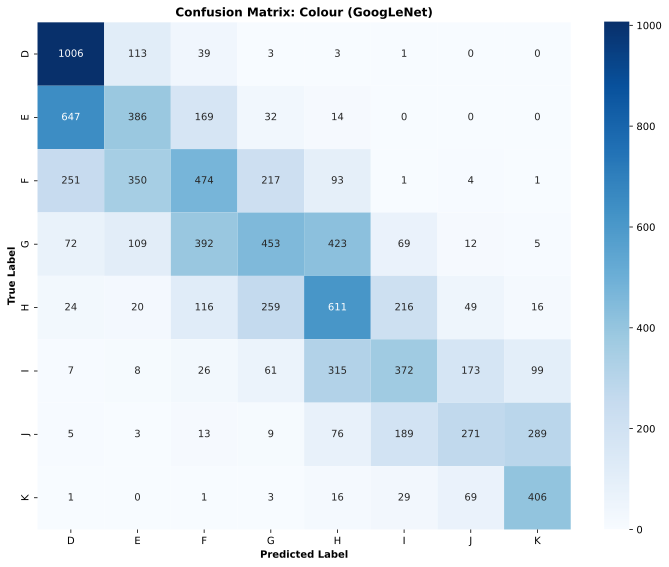

In [43]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm_colour = confusion_matrix(all_labels_colour, all_preds_colour)

plt.figure(figsize=(10, 8))
sns.heatmap(cm_colour, annot=True, fmt='d', cmap='Blues',
            xticklabels=colour_classes, yticklabels=colour_classes)
plt.title('Confusion Matrix: Colour (GoogLeNet)', fontweight='bold', fontsize=12)
plt.ylabel('True Label', fontweight='bold')
plt.xlabel('Predicted Label', fontweight='bold')
plt.tight_layout()
plt.show()

## 8. Example

Pick a random test image and visually compare the model's colour prediction against the true label, as a quick qualitative sanity check.

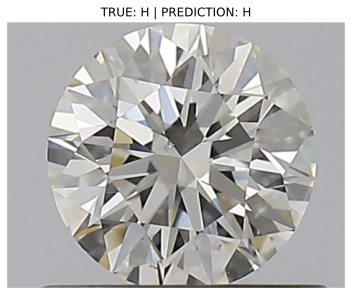

In [47]:
def predict_random_image_colour():
    net_colour.eval()
    sample_row = test_df_colour.sample(1).iloc[0]
    img_path = os.path.join(local_dir, sample_row['path_to_img'])
    img = Image.open(img_path).convert('RGB')

    img_tensor = data_transforms_colour(img).unsqueeze(0).to(device)

    with torch.no_grad():
        output = net_colour(img_tensor)
        predicted_idx = torch.argmax(output, dim=1)

    predicted_colour = test_dataset_colour.colours[predicted_idx.item()]
    true_colour = sample_row['colour']

    plt.imshow(img)
    plt.title(f"TRUE: {true_colour} | PREDICTION: {predicted_colour}")
    plt.axis('off')
    plt.show()

predict_random_image_colour()

# Colour × Symmetry Classification

For the final sub-task of the project, I combine two attributes — **colour** and **symmetry** — into a single, more challenging classification target. Rather than training two separate models, I build one combined categorical label (`colour_symmetry`) that captures both dimensions at once, resulting in up to 8 × 2 = 16 possible classes.

Since the `symmetry` column originally contains more than two categories, I first restrict it to the **top 2 most frequent symmetry grades**, which together already account for roughly 94% of the dataset. This keeps the number of combined classes manageable and avoids training on symmetry categories that are too rare to be reliably learned. I then filter the dataset to the same main colour range (`D` to `K`) used in Part 2, and construct the combined label by concatenating the colour and symmetry strings. Finally, I perform a stratified 80/20 train/test split directly on this combined label, to preserve the relative frequency of each colour-symmetry pair in both subsets, and align the image paths to the local cache as done for the previous tasks.

## 1. Data Preparation

In [48]:
import pandas as pd
from sklearn.model_selection import train_test_split

# --- DIAGNOSTIC: inspect the full symmetry distribution before filtering ---
print("All symmetry categories in the original dataset:")
print(df['symmetry'].value_counts())

# Automatically identify the top 2 most frequent symmetry categories (~94% of dataset)
top_symmetries = df['symmetry'].value_counts().nlargest(2).index.tolist()
print(f"\nTop 2 symmetry categories kept: {top_symmetries}")

discarded_symmetries = [s for s in df['symmetry'].unique() if s not in top_symmetries]
print(f"Discarded categories: {discarded_symmetries}")

# Filter dataset for top symmetries and main colours (D to K, excluding L, M, N
# to avoid combined classes that are too small for a stratified split)
df_filtered = df[df['symmetry'].isin(top_symmetries)].reset_index(drop=True)
print(f"\nSamples remaining after symmetry filtering: {len(df_filtered)} (out of {len(df)} original samples)")

main_colours = ['D', 'E', 'F', 'G', 'H', 'I', 'J', 'K']
df_filtered = df_filtered[df_filtered['colour'].isin(main_colours)].reset_index(drop=True)
print(f"Samples remaining after colour filtering: {len(df_filtered)}")

# Create the cross target column (8 colours * 2 symmetries = 16 classes)
df_filtered['colour_symmetry'] = df_filtered['colour'] + "_" + df_filtered['symmetry']

# --- DIAGNOSTIC: check for combined classes with too few samples before stratified splitting ---
print("\nDistribution of combined colour_symmetry classes (sorted by increasing frequency):")
print(df_filtered['colour_symmetry'].value_counts().sort_values())

# Stratified split 80/20
train_df_cross, test_df_cross = train_test_split(
    df_filtered,
    test_size=0.2,
    stratify=df_filtered['colour_symmetry'],
    random_state=42
)

# Align paths for local cache
train_df_cross = train_df_cross.copy()
test_df_cross = test_df_cross.copy()
train_df_cross['path_to_img'] = train_df_cross['path_to_img'].str.replace('web_scraped/', '', regex=False)
test_df_cross['path_to_img'] = test_df_cross['path_to_img'].str.replace('web_scraped/', '', regex=False)

print(f"\nFiltered samples: {len(df_filtered)} | Combined classes: {df_filtered['colour_symmetry'].nunique()}")
print(f"Train samples: {len(train_df_cross)} | Test samples: {len(test_df_cross)}")

All symmetry categories in the original dataset:
symmetry
EX    23618
VG    22161
GD     2840
F       108
G        33
PR        1
Name: count, dtype: int64

Top 2 symmetry categories kept: ['EX', 'VG']
Discarded categories: ['GD', 'G', 'F', nan, 'PR']

Samples remaining after symmetry filtering: 45779 (out of 48763 original samples)
Samples remaining after colour filtering: 42732

Distribution of combined colour_symmetry classes (sorted by increasing frequency):
colour_symmetry
K_VG    1180
K_EX    1311
J_VG    1997
J_EX    2029
I_VG    2343
I_EX    2618
D_EX    2730
E_VG    2767
D_VG    2774
H_VG    2927
E_EX    3121
F_VG    3142
H_EX    3193
F_EX    3384
G_VG    3539
G_EX    3677
Name: count, dtype: int64

Filtered samples: 42732 | Combined classes: 16
Train samples: 34185 | Test samples: 8547


## 2. Exploratory Data Analysis

Before building the Dataset class, I inspect the distribution of the 16 combined colour-symmetry classes. Since this label is the cross-product of two independent attributes, some combinations are naturally much rarer than others — understanding this imbalance is especially important here, given the higher number of classes and the reduced sample size after filtering.


---  Diamond Colour x Symmetry Classes ---
colour_symmetry
G_EX    3677
G_VG    3539
F_EX    3384
H_EX    3193
F_VG    3142
E_EX    3121
H_VG    2927
D_VG    2774
E_VG    2767
D_EX    2730
I_EX    2618
I_VG    2343
J_EX    2029
J_VG    1997
K_EX    1311
K_VG    1180
Name: count, dtype: int64


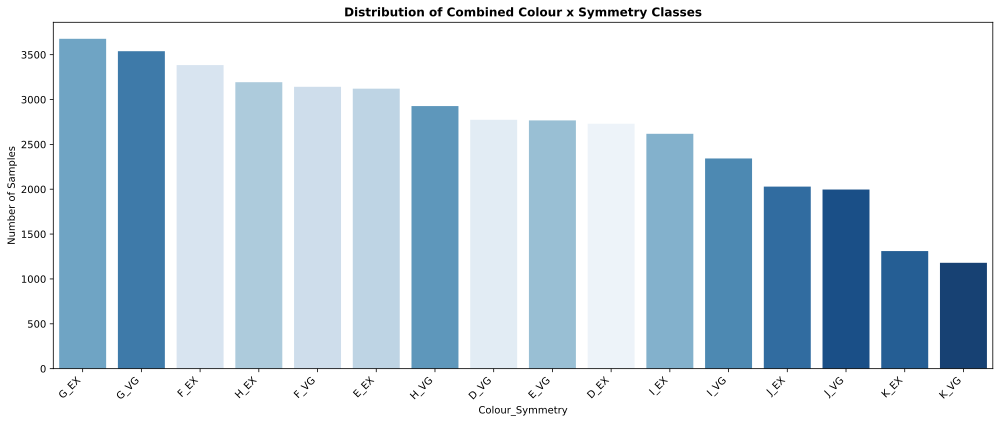

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns

# Print raw class counts for the combined colour-symmetry label
print("\n---  Diamond Colour x Symmetry Classes ---")
print(df_filtered['colour_symmetry'].value_counts())

# Visualize the class distribution as a bar plot, ordered by frequency
plt.figure(figsize=(14, 6))
order = df_filtered['colour_symmetry'].value_counts().index
sns.countplot(
    data=df_filtered,
    x='colour_symmetry',
    order=order,
    hue='colour_symmetry',
    palette='Blues_r',
    legend=False
)
plt.title('Distribution of Combined Colour x Symmetry Classes', fontweight='bold', fontsize=12)
plt.xlabel('Colour_Symmetry')
plt.ylabel('Number of Samples')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 3. Custom Dataset & DataLoader

I now build the data pipeline for the combined colour-symmetry task: a custom `Dataset` class that lazy-loads images and maps their combined colour-symmetry label to an integer class ID, and the corresponding `DataLoader` objects for batch training. Since the combined label was already split in a stratified manner, I compute the list of possible classes once on the full filtered dataset, before splitting, to guarantee that both the training and test `Dataset` objects use identical label mappings.

In [50]:
train_ids_cross = set(train_df_cross['stock_number'].astype(str))
test_ids_cross = set(test_df_cross['stock_number'].astype(str))
overlap_cross = train_ids_cross & test_ids_cross
print(f"Diamanti duplicati tra train e test (cross): {len(overlap_cross)}")
if overlap_cross:
    print(" Possibile leakage:", list(overlap_cross)[:5])
else:
    print("✅ no leakage ")

Diamanti duplicati tra train e test (cross): 0
✅ no leakage 


In [51]:
import os
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# 1. Define the Data Preprocessing Pipeline
# - Resize: Enforces a uniform spatial resolution (96x96), required as input size for GoogLeNet.
# - ToTensor: Converts the PIL Image into a 32-bit floating-point PyTorch tensor
#   and normalizes the pixel intensity values from [0, 255] to the [0.0, 1.0] range.
# - Normalize: Standardizes each RGB channel using ImageNet mean/std, consistent with
#   the Colour task, which helps the network learn subtle colour cues within this combined target.
data_transforms_cross = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 2. Compute the combined class list once on the full filtered dataset, before splitting,
# to guarantee consistent label indices between train and test sets.
cross_classes = sorted(df_filtered['colour_symmetry'].unique())

# 3. Custom Dataset Implementation
class DiamondCross(Dataset):
    """
    Custom PyTorch Dataset class designed to lazy-load diamond images and their
    corresponding combined colour-symmetry target labels from the local filesystem.
    """
    def __init__(self, dataframe, base_dir, classes, transform=None):
        self.data = dataframe.reset_index(drop=True)
        self.base_dir = base_dir
        self.transform = transform
        self.classes = classes
        self.class_map = {name: i for i, name in enumerate(self.classes)}

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        rel_path = str(self.data.iloc[idx]['path_to_img'])
        img_path = os.path.join(self.base_dir, rel_path)
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        label = torch.tensor(self.class_map[self.data.iloc[idx]['colour_symmetry']], dtype=torch.long)
        return image, label

# 4. Instantiate the Custom Datasets
train_dataset_cross = DiamondCross(train_df_cross, local_dir, cross_classes, transform=data_transforms_cross)
test_dataset_cross = DiamondCross(test_df_cross, local_dir, cross_classes, transform=data_transforms_cross)

# 5. Configure DataLoaders for Batch Generation
batch_size = 128
train_iter_cross = DataLoader(train_dataset_cross, batch_size=batch_size, shuffle=True, num_workers=2)
test_iter_cross = DataLoader(test_dataset_cross, batch_size=batch_size, shuffle=False, num_workers=2)

## 4. Convolutional Neural Network Architecture — GoogLeNet

For the combined colour-symmetry task, I reuse the same GoogLeNet architecture designed for the colour task. However, since `b1` to `b5` are stateful PyTorch modules already bound (with their own trained weights) to `net_colour`, I redefine the `Inception` blocks and the sequential blocks from scratch here, so that `net_cross` has its own independent set of parameters and does not share weights with `net_colour`. Only the final fully connected layer differs in size, outputting a prediction over the 16 combined colour-symmetry classes instead of 8.

In [52]:
import torch
import torch.nn as nn
from torch.nn import functional as F

class InceptionCross(nn.Module):
    def __init__(self, in_channels, c1, c2, c3, c4, **kwargs):
        super(InceptionCross, self).__init__(**kwargs)
        self.p1_1 = nn.Conv2d(in_channels, c1, kernel_size=1)
        self.p2_1 = nn.Conv2d(in_channels, c2[0], kernel_size=1)
        self.p2_2 = nn.Conv2d(c2[0], c2[1], kernel_size=3, padding=1)
        self.p3_1 = nn.Conv2d(in_channels, c3[0], kernel_size=1)
        self.p3_2 = nn.Conv2d(c3[0], c3[1], kernel_size=5, padding=2)
        self.p4_1 = nn.MaxPool2d(kernel_size=3, stride=1, padding=1)
        self.p4_2 = nn.Conv2d(in_channels, c4, kernel_size=1)

    def forward(self, x):
        p1 = F.relu(self.p1_1(x))
        p2 = F.relu(self.p2_2(F.relu(self.p2_1(x))))
        p3 = F.relu(self.p3_2(F.relu(self.p3_1(x))))
        p4 = F.relu(self.p4_2(self.p4_1(x)))
        return torch.cat((p1, p2, p3, p4), dim=1)

# GoogLeNet modules (independent instance, adapted for 3-channel RGB images)
b1_cross = nn.Sequential(
    nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
)
b2_cross = nn.Sequential(
    nn.Conv2d(64, 64, kernel_size=1),
    nn.ReLU(),
    nn.Conv2d(64, 192, kernel_size=3, padding=1),
    nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
)
b3_cross = nn.Sequential(
    InceptionCross(192, 64, (96, 128), (16, 32), 32),
    InceptionCross(256, 128, (128, 192), (32, 96), 64),
    nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
)
b4_cross = nn.Sequential(
    InceptionCross(480, 192, (96, 208), (16, 48), 64),
    InceptionCross(512, 160, (112, 224), (24, 64), 64),
    InceptionCross(512, 128, (128, 256), (24, 64), 64),
    InceptionCross(512, 112, (144, 288), (32, 64), 64),
    InceptionCross(528, 256, (160, 320), (32, 128), 128),
    nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
)
b5_cross = nn.Sequential(
    InceptionCross(832, 256, (160, 320), (32, 128), 128),
    InceptionCross(832, 384, (192, 384), (48, 128), 128),
    nn.AdaptiveAvgPool2d((1, 1)),
    nn.Flatten()
)

# Final GoogLeNet model adapted for 16 combined colour-symmetry classes
net_cross = nn.Sequential(b1_cross, b2_cross, b3_cross, b4_cross, b5_cross, nn.Linear(1024, 16))

## 5. Model Training & Validation Execution

I now train the GoogLeNet model on the combined colour-symmetry task, reusing the same generic `train` function defined earlier. I use the same hyperparameters as the colour task (learning rate `0.01`, 10 epochs), tracking both training and validation accuracy at each epoch. Once training completes, I save the model's weights directly to Google Drive for persistence across sessions.


✅ Training Completed:
Final Training Loss: 1.648
Final Training Accuracy: 0.384
Final Validation Accuracy: 0.339
✅ GoogLeNet colour x symmetry model successfully saved to: /content/drive/MyDrive/Progetto diamanti /modello_cross_googlenet.pth


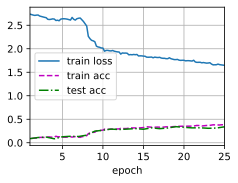

In [53]:
from d2l import torch as d2l
import os

# Training hyperparameters
lr, num_epochs = 0.01, 25

# Start training with GoogLeNet
train(net_cross, train_iter_cross, test_iter_cross, num_epochs, lr, device=d2l.try_gpu())

# Save weights to Google Drive
model_save_path = os.path.join(base_dir, 'modello_cross_googlenet.pth')
torch.save(net_cross.state_dict(), model_save_path)
print(f"✅ GoogLeNet colour x symmetry model successfully saved to: {model_save_path}")

## 6. Model Evaluation

After training, I evaluate the GoogLeNet model's per-class performance on the combined colour-symmetry task by running inference over the entire validation set and computing precision, recall and f1-score for each of the 16 combined classes.

In [54]:
# Evaluate the trained model on the entire validation set and generate
# a per-class classification report (precision, recall, f1-score) for the colour x symmetry task.

import torch
from sklearn.metrics import classification_report

device = next(net_cross.parameters()).device
net_cross.eval()

# Lists to accumulate all predictions and ground-truth labels for the cross task
all_preds_cross = []
all_labels_cross = []


with torch.no_grad():
    for X, y in test_iter_cross:
        X = X.to(device)
        y_hat = net_cross(X)
        preds = torch.argmax(y_hat, dim=1)
        all_preds_cross.extend(preds.cpu().numpy())
        all_labels_cross.extend(y.numpy())

# Retrieve the class names from the test dataset
cross_classes = list(test_dataset_cross.classes)

# --- TEXT REPORT ---
print("\n" + "="*60)
print("DIAMOND CROSS CLASSIFICATION (Colour x Symmetry) - REPORT")
print("="*60)
print(classification_report(all_labels_cross, all_preds_cross, target_names=cross_classes))


DIAMOND CROSS CLASSIFICATION (Colour x Symmetry) - REPORT
              precision    recall  f1-score   support

        D_EX       0.40      0.32      0.36       546
        D_VG       0.43      0.71      0.53       555
        E_EX       0.39      0.23      0.29       624
        E_VG       0.30      0.34      0.32       553
        F_EX       0.28      0.25      0.27       677
        F_VG       0.32      0.31      0.31       628
        G_EX       0.37      0.14      0.21       736
        G_VG       0.30      0.48      0.37       708
        H_EX       0.34      0.34      0.34       639
        H_VG       0.31      0.42      0.35       585
        I_EX       0.26      0.14      0.18       524
        I_VG       0.32      0.22      0.26       469
        J_EX       0.32      0.22      0.26       406
        J_VG       0.30      0.54      0.39       399
        K_EX       0.51      0.42      0.46       262
        K_VG       0.44      0.58      0.50       236

    accuracy         

## 7. Confusion Matrix

To better visualize where the model confuses adjacent colour-symmetry combinations, I plot the confusion matrix using the predictions and ground-truth labels computed in the previous step. Given the higher number of classes (16), I omit the per-cell numeric annotations to keep the plot readable.

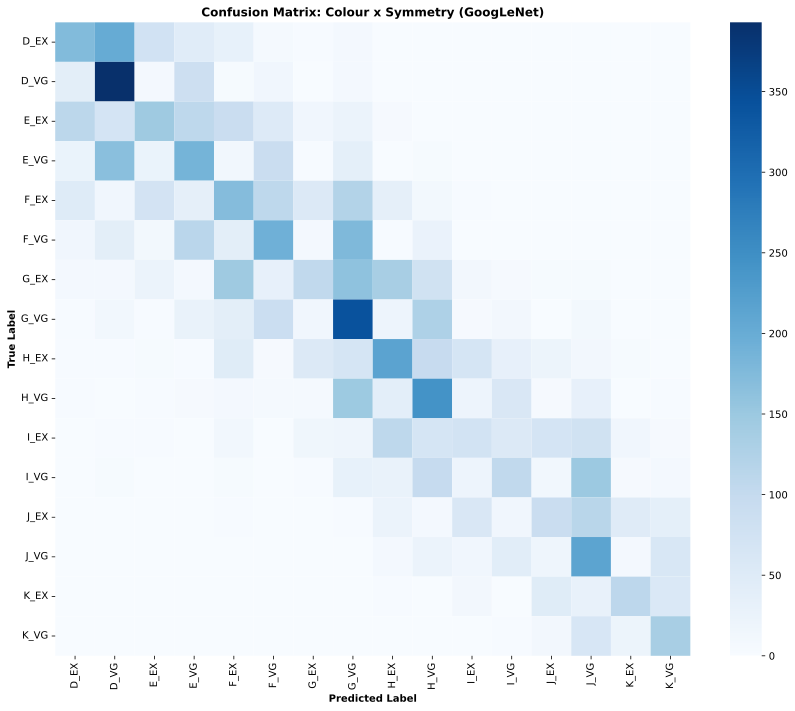

In [55]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm_cross = confusion_matrix(all_labels_cross, all_preds_cross)

plt.figure(figsize=(12, 10))
sns.heatmap(cm_cross, annot=False, fmt='d', cmap='Blues',
            xticklabels=cross_classes, yticklabels=cross_classes)
plt.title('Confusion Matrix: Colour x Symmetry (GoogLeNet)', fontweight='bold', fontsize=12)
plt.ylabel('True Label', fontweight='bold')
plt.xlabel('Predicted Label', fontweight='bold')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 8. Qualitative Check

As a final sanity check, I pick a random test image and visually compare the model's combined colour-symmetry prediction against the true label.

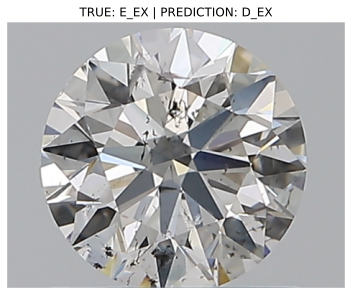

In [56]:
# Pick a random test image and visually compare the model's colour-symmetry prediction
# against the true label, as a quick qualitative sanity check.

def predict_random_image_cross():
    net_cross.eval()
    sample_row = test_df_cross.sample(1).iloc[0]
    img_path = os.path.join(local_dir, sample_row['path_to_img'])
    img = Image.open(img_path).convert('RGB')

    img_tensor = data_transforms_cross(img).unsqueeze(0).to(device)

    with torch.no_grad():
        output = net_cross(img_tensor)
        predicted_idx = torch.argmax(output, dim=1)

    predicted_cross = test_dataset_cross.classes[predicted_idx.item()]
    true_cross = sample_row['colour_symmetry']

    plt.imshow(img)
    plt.title(f"TRUE: {true_cross} | PREDICTION: {predicted_cross}")
    plt.axis('off')
    plt.show()

predict_random_image_cross()